# Breast Cancer EDA Project
**Dataset:** Breast_Cancer.csv (4024 patients, 16 columns)

**Goal:** Samajhna ke kaun se factors (stage, hormone status, age, tumor size) patient ke survive karne ya na karne se juray hain.

**Note:** Is dataset mein koi date column nahi hai, is liye Time-Series ke liye `Survival_Months` (follow-up time) use kiya gaya hai.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Data Understanding

In [2]:
#load dataset
df = pd.read_csv("/content/Breast_Cancer.csv")

In [3]:
df.head() #first 5 rows

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [4]:
df.tail() #last 5 rows

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
4019,62,Other,Married,T1,N1,IIA,Moderately differentiated,2,Regional,9,Positive,Positive,1,1,49,Alive
4020,56,White,Divorced,T2,N2,IIIA,Moderately differentiated,2,Regional,46,Positive,Positive,14,8,69,Alive
4021,68,White,Married,T2,N1,IIB,Moderately differentiated,2,Regional,22,Positive,Negative,11,3,69,Alive
4022,58,Black,Divorced,T2,N1,IIB,Moderately differentiated,2,Regional,44,Positive,Positive,11,1,72,Alive
4023,46,White,Married,T2,N1,IIB,Moderately differentiated,2,Regional,30,Positive,Positive,7,2,100,Alive


In [5]:
df  #first and last both rows

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4019,62,Other,Married,T1,N1,IIA,Moderately differentiated,2,Regional,9,Positive,Positive,1,1,49,Alive
4020,56,White,Divorced,T2,N2,IIIA,Moderately differentiated,2,Regional,46,Positive,Positive,14,8,69,Alive
4021,68,White,Married,T2,N1,IIB,Moderately differentiated,2,Regional,22,Positive,Negative,11,3,69,Alive
4022,58,Black,Divorced,T2,N1,IIB,Moderately differentiated,2,Regional,44,Positive,Positive,11,1,72,Alive


In [6]:
df.sample() #1 random row

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
1132,61,White,Divorced,T2,N1,IIB,Moderately differentiated,2,Regional,23,Negative,Negative,23,7,92,Alive


In [7]:
df.shape  #(Rows, Columns)

(4024, 16)

In [8]:
df.dtypes  #each column datatype

,0
Age,int64
Race,object
Marital Status,object
T Stage,object
N Stage,object
6th Stage,object
differentiate,object
Grade,object
A Stage,object
Tumor Size,int64


In [9]:
df.info()  #non-null count, data type, missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Age                     4024 non-null   int64 
 1   Race                    4024 non-null   object
 2   Marital Status          4024 non-null   object
 3   T Stage                 4024 non-null   object
 4   N Stage                 4024 non-null   object
 5   6th Stage               4024 non-null   object
 6   differentiate           4024 non-null   object
 7   Grade                   4024 non-null   object
 8   A Stage                 4024 non-null   object
 9   Tumor Size              4024 non-null   int64 
 10  Estrogen Status         4024 non-null   object
 11  Progesterone Status     4024 non-null   object
 12  Regional Node Examined  4024 non-null   int64 
 13  Reginol Node Positive   4024 non-null   int64 
 14  Survival Months         4024 non-null   int64 
 15  Stat

In [10]:
#Numerical aur Categorical columns alag karrahe ha kyuke har type ka analysis different hota hai.
num_cols = df.select_dtypes(include= "number").columns.to_list()
cat_cols = df.select_dtypes(exclude= "number").columns.to_list()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive', 'Survival Months']
Categorical: ['Race', 'Marital Status', 'T Stage ', 'N Stage', '6th Stage', 'differentiate', 'Grade', 'A Stage', 'Estrogen Status', 'Progesterone Status', 'Status']


In [11]:
df.describe().T  # mean, median(50%), std, min, max

,count,mean,std,min,25%,50%,75%,max
Age,4024.0,53.972167,8.963134,30.0,47.0,54.0,61.0,69.0
Tumor Size,4024.0,30.473658,21.119696,1.0,16.0,25.0,38.0,140.0
Regional Node Examined,4024.0,14.357107,8.099675,1.0,9.0,14.0,19.0,61.0
Reginol Node Positive,4024.0,4.158052,5.109331,1.0,1.0,2.0,5.0,46.0
Survival Months,4024.0,71.297962,22.921430,1.0,56.0,73.0,90.0,107.0


# Data Cleaning

In [12]:
df.isnull().sum()  # missing values check

,0
Age,0
Race,0
Marital Status,0
T Stage,0
N Stage,0
6th Stage,0
differentiate,0
Grade,0
A Stage,0
Tumor Size,0


In [13]:
# Observation: Koi missing value nahi hai, is liye fill ya drop ki zaroorat nahi.
# Agar hoti to ye methods use karte:
# df["Age"].fillna(df["Age"].median(), inplace=True)   # numeric column -> median se fill hota
# df.dropna(inplace=True)                              # ya missing rows delete kardete

In [14]:
df.duplicated().sum()   #how much duplicate rows

np.int64(1)

In [15]:
df.drop_duplicates(inplace=True)   # duplicate row delete

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
# Cleaning of column names: extra space hataya ha, typo theek kiya ha, underscore lagaya ha
df.columns = df.columns.str.strip()   # 'T Stage ' -> 'T Stage'
df.rename(columns={"Reginol Node Positive": "Nodes_Positive",
                   "Regional Node Examined": "Nodes_Examined",
                   "6th Stage": "Stage",
                   "differentiate": "Differentiate"}, inplace=True)
df.columns = df.columns.str.replace(" ", "_")
df.columns

Index(['Age', 'Race', 'Marital_Status', 'T_Stage', 'N_Stage', 'Stage',
       'Differentiate', 'Grade', 'A_Stage', 'Tumor_Size', 'Estrogen_Status',
       'Progesterone_Status', 'Nodes_Examined', 'Nodes_Positive',
       'Survival_Months', 'Status'],
      dtype='object')

In [18]:
# Text values ke extra space hatana ha (jaise 'Single ' -> 'Single')
for c in df.select_dtypes(exclude= "number").columns:
  df[c] = df[c].str.strip()
df["Marital_Status"].unique()

array(['Married', 'Divorced', 'Single', 'Widowed', 'Separated'],
      dtype=object)

In [19]:
#Grade column ma label ha
df["Grade"].unique()

array(['3', '2', '1', 'anaplastic; Grade IV'], dtype=object)

In [20]:
df["Grade"] = df["Grade"].replace({"anaplastic; Grade IV": "4"})
df["Grade"] = df["Grade"].astype(int)   # data type theek karna: text -> number

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4023 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Age                  4023 non-null   int64 
 1   Race                 4023 non-null   object
 2   Marital_Status       4023 non-null   object
 3   T_Stage              4023 non-null   object
 4   N_Stage              4023 non-null   object
 5   Stage                4023 non-null   object
 6   Differentiate        4023 non-null   object
 7   Grade                4023 non-null   int64 
 8   A_Stage              4023 non-null   object
 9   Tumor_Size           4023 non-null   int64 
 10  Estrogen_Status      4023 non-null   object
 11  Progesterone_Status  4023 non-null   object
 12  Nodes_Examined       4023 non-null   int64 
 13  Nodes_Positive       4023 non-null   int64 
 14  Survival_Months      4023 non-null   int64 
 15  Status               4023 non-null   object
dtypes: int64(6)

In [21]:
# Differentiate aur Grade same information hain, is liye ek drop kar diya
df.drop(columns=["Differentiate"], inplace=True)
df.head()

,Age,Race,Marital_Status,T_Stage,N_Stage,Stage,Grade,A_Stage,Tumor_Size,Estrogen_Status,Progesterone_Status,Nodes_Examined,Nodes_Positive,Survival_Months,Status
0,68,White,Married,T1,N1,IIA,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,3,Regional,41,Positive,Positive,3,1,50,Alive


In [22]:
# Date column nahi hai is liye to_datetime ki zaroorat nahi.
# Logic check: positive nodes examined nodes se zyada nahi ho sakti
(df["Nodes_Positive"] > df["Nodes_Examined"]).sum()   # 0 ana chahiye

np.int64(0)

Text(0.5, 1.0, 'The Spread of Tumor Size')

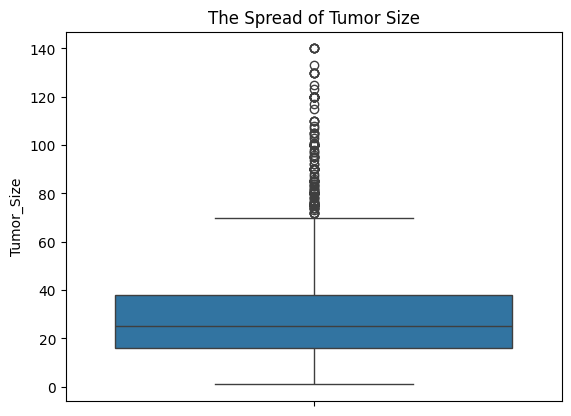

In [23]:
sns.boxplot(y = df["Tumor_Size"])
plt.title("The Spread of Tumor Size")

In [24]:
#Outliers are real patients with large tumors, so I kept them.

Text(0.5, 1.0, 'The Spread of Positive Nodes')

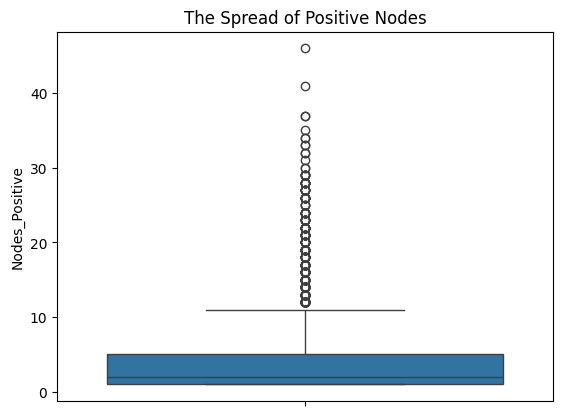

In [25]:
sns.boxplot(y = df["Nodes_Positive"])
plt.title("The Spread of Positive Nodes")

In [26]:
#Outliers are valid severe cases, so I kept them.

# Feature Engineering

In [27]:
df["Dead"] = (df["Status"] == "Dead").astype(int) # Dead = 1, Alive = 0 (mortality % nikalne ke liye)
df.head()

,Age,Race,Marital_Status,T_Stage,N_Stage,Stage,Grade,A_Stage,Tumor_Size,Estrogen_Status,Progesterone_Status,Nodes_Examined,Nodes_Positive,Survival_Months,Status,Dead
0,68,White,Married,T1,N1,IIA,3,Regional,4,Positive,Positive,24,1,60,Alive,0
1,50,White,Married,T2,N2,IIIA,2,Regional,35,Positive,Positive,14,5,62,Alive,0
2,58,White,Divorced,T3,N3,IIIC,2,Regional,63,Positive,Positive,14,7,75,Alive,0
3,58,White,Married,T1,N1,IIA,3,Regional,18,Positive,Positive,2,1,84,Alive,0
4,47,White,Married,T2,N1,IIB,3,Regional,41,Positive,Positive,3,1,50,Alive,0


In [28]:
df["Nodes_Ratio"] = df["Nodes_Positive"] / df["Nodes_Examined"] * 100   # kitne % nodes mein cancer mila

In [29]:
df["Age_Group"] = pd.cut(df["Age"], bins = [29, 39, 49, 59, 69], labels = ["30-39", "40-49", "50-59", "60-69"])

In [30]:
df["Tumor_Size_Group"] = pd.cut(df["Tumor_Size"], bins = [0, 20, 50, 200], labels = ["Small", "Medium", "Large"])

In [31]:
df["Hormone_Profile"] = "ER" + df["Estrogen_Status"] + " / PR " + df["Progesterone_Status"]

In [32]:
df["Follow_Up_Year"] = df["Survival_Months"] // 12 + 1   # months ko years main karna (time-series ke liye)
df.head()

,Age,Race,Marital_Status,T_Stage,N_Stage,Stage,Grade,A_Stage,Tumor_Size,Estrogen_Status,...,Nodes_Examined,Nodes_Positive,Survival_Months,Status,Dead,Nodes_Ratio,Age_Group,Tumor_Size_Group,Hormone_Profile,Follow_Up_Year
0,68,White,Married,T1,N1,IIA,3,Regional,4,Positive,...,24,1,60,Alive,0,4.166667,60-69,Small,ERPositive / PR Positive,6
1,50,White,Married,T2,N2,IIIA,2,Regional,35,Positive,...,14,5,62,Alive,0,35.714286,50-59,Medium,ERPositive / PR Positive,6
2,58,White,Divorced,T3,N3,IIIC,2,Regional,63,Positive,...,14,7,75,Alive,0,50.000000,50-59,Large,ERPositive / PR Positive,7
3,58,White,Married,T1,N1,IIA,3,Regional,18,Positive,...,2,1,84,Alive,0,50.000000,50-59,Small,ERPositive / PR Positive,8
4,47,White,Married,T2,N1,IIB,3,Regional,41,Positive,...,3,1,50,Alive,0,33.333333,40-49,Medium,ERPositive / PR Positive,5


# EDA (Exploratory Data Analysis)

## Univariate (1 column)

Text(0.5, 1.0, 'Distribution of Age')

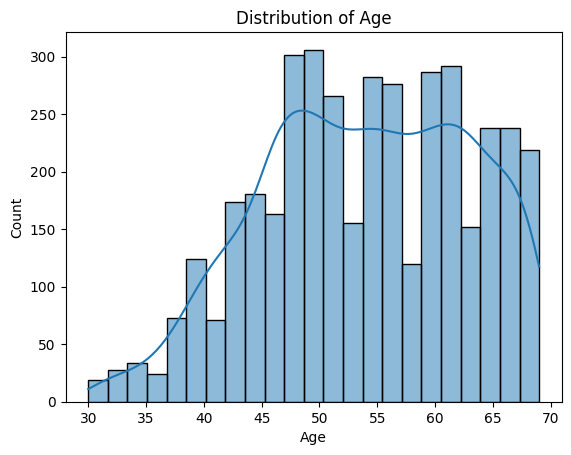

In [33]:
sns.histplot(df["Age"], kde= True)
plt.title("Distribution of Age")

Text(0.5, 1.0, 'Distribution of Tumor Size')

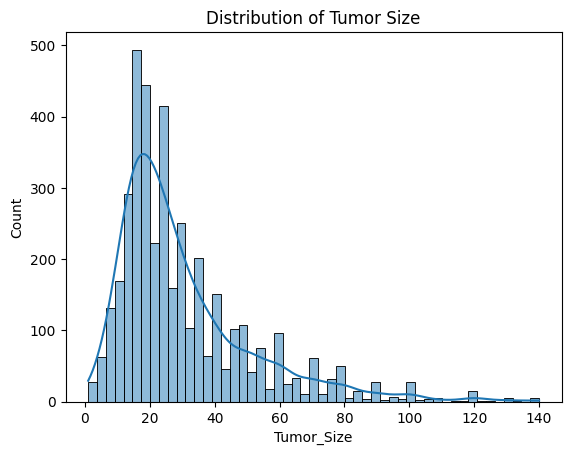

In [34]:
sns.histplot(df["Tumor_Size"], kde= True )
plt.title("Distribution of Tumor Size")

Text(0.5, 1.0, 'Count of Each Stage')

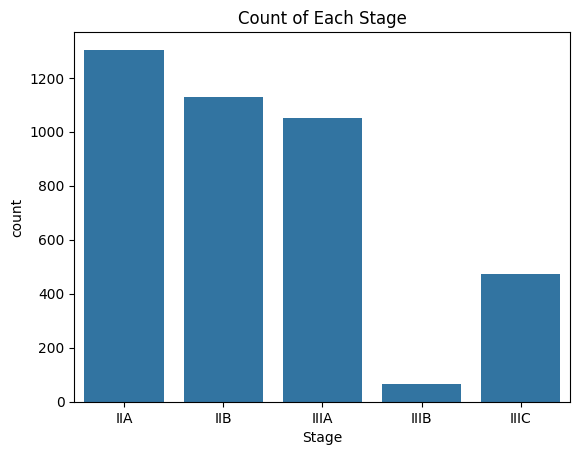

In [35]:
sns.countplot(x = "Stage", data = df, order = ["IIA", "IIB", "IIIA", "IIIB", "IIIC"])
plt.title("Count of Each Stage")

Text(0.5, 1.0, 'Alive vs Dead')

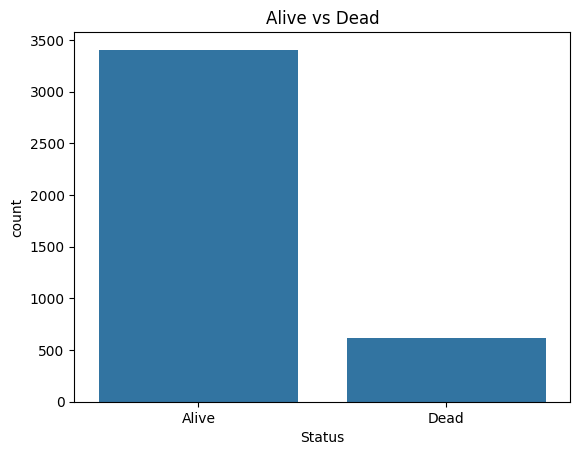

In [36]:
sns.countplot(x = "Status", data= df)
plt.title("Alive vs Dead")

## Bivariate (2 columns)

Text(0.5, 1.0, 'Tumor Size VS Survival Months')

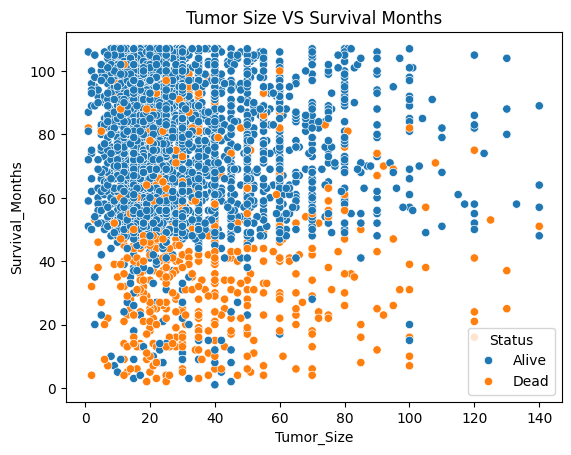

In [37]:
sns.scatterplot(data= df, x = "Tumor_Size", y = "Survival_Months", hue= "Status")
plt.title("Tumor Size VS Survival Months")

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'IIA'),
  Text(1, 0, 'IIB'),
  Text(2, 0, 'IIIA'),
  Text(3, 0, 'IIIB'),
  Text(4, 0, 'IIIC')])

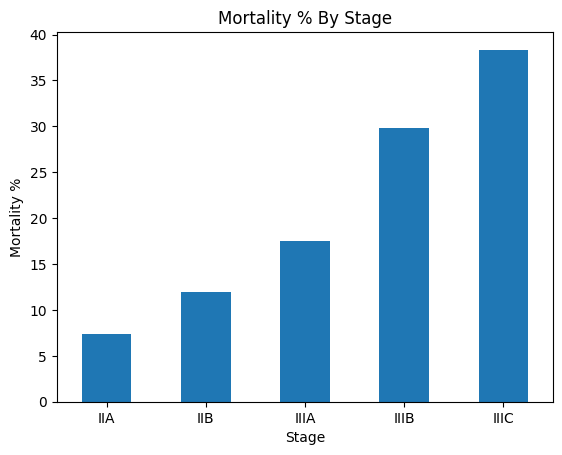

In [38]:
df.groupby("Stage")["Dead"].mean().mul(100).plot(kind= "bar")
plt.ylabel("Mortality %")
plt.title("Mortality % By Stage")
plt.xticks(rotation= 0)

(array([0, 1]), [Text(0, 0, 'Negative'), Text(1, 0, 'Positive')])

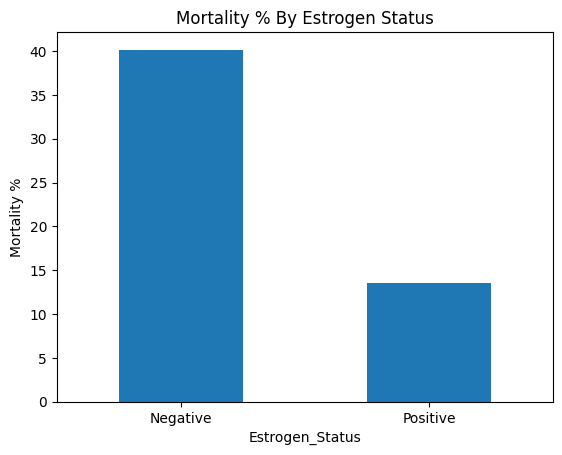

In [39]:
df.groupby("Estrogen_Status")["Dead"].mean().mul(100).plot(kind= "bar")
plt.ylabel("Mortality %")
plt.title("Mortality % By Estrogen Status")
plt.xticks(rotation= 0)

## Multivariate (3 Columns)

In [40]:
# Mortality % : Stage x Estrogen Status
pd.pivot_table(df, values= "Dead", index= "Stage", columns= "Estrogen_Status", aggfunc= "mean").mul(100).round(1)

Estrogen_Status,Negative,Positive
Stage,,
IIA,13.6,7.1
IIB,33.3,10.7
IIIA,41.3,15.7
IIIB,63.6,23.2
IIIC,67.2,34.1


In [41]:
# Mortality % : T Stage x N Stage
pd.pivot_table(df, values= "Dead", index= "T_Stage", columns= "N_Stage", aggfunc= "mean").mul(100).round(1)

N_Stage,N1,N2,N3
T_Stage,,,
T1,7.4,14.7,34.5
T2,11.9,20.6,35.1
T3,11.8,22.8,41.8
T4,22.9,37.5,57.1


## Time-Series

In [42]:
# Date nahi hai, is liye Follow_Up_Year use kiya. Kitne patients ki death kis saal mein hui:
df[df["Dead"] == 1].groupby("Follow_Up_Year").size()

,0
Follow_Up_Year,
1,44
2,81
3,99
4,118
5,107
6,66
7,55
8,32
9,14


In [43]:
# Average survival months stage ke hisaab se
df.groupby("Stage")["Survival_Months"].mean().round(1)

,Survival_Months
Stage,
IIA,74.4
IIB,72.2
IIIA,70.2
IIIB,69.4
IIIC,63.2


# Business Questions

1. Which stage has the highest mortality?

In [44]:
df.groupby("Stage")["Dead"].mean().mul(100).round(1)

,Dead
Stage,
IIA,7.4
IIB,11.9
IIIA,17.5
IIIB,29.9
IIIC,38.3


In [ ]:
#Stage IIA has lowest mortality (~7.4%), Stage IIIC has highest (~38.3%), about 5 times higher.

2. Does hormone receptor (Estrogen / Progesterone) status affect survival?

In [45]:
df.groupby("Estrogen_Status")["Dead"].mean().mul(100).round(1)

,Dead
Estrogen_Status,
Negative,40.1
Positive,13.5


In [46]:
df.groupby("Progesterone_Status")["Dead"].mean().mul(100).round(1)

,Dead
Progesterone_Status,
Negative,29.2
Positive,12.4


In [ ]:
#Estrogen negative patients: ~40.1% mortality vs positive ~13.5%. Progesterone negative ~29.2% vs positive ~12.4%.

3. Which age group is most at risk?

In [47]:
df.groupby("Age_Group")["Dead"].mean().mul(100).round(1)

,Dead
Age_Group,
30-39,20.4
40-49,12.1
50-59,13.6
60-69,19.1


In [ ]:
#Youngest (30-39: ~20.4%) and oldest (60-69: ~19.1%) groups have the highest mortality. 40-49 is lowest (~12.1%).

4. Does tumor size affect survival?

In [48]:
df.groupby("Tumor_Size_Group")["Dead"].mean().mul(100).round(1)

,Dead
Tumor_Size_Group,
Small,10.1
Medium,17.4
Large,23.3


In [49]:
df["Tumor_Size"].corr(df["Dead"])

np.float64(0.134147488951224)

In [ ]:
#Yes, mortality rises with size: Small ~10.1%, Medium ~17.4%, Large ~23.3%. But correlation is only ~0.13 (weak on its own).

5. In which follow-up year do most deaths happen?

In [50]:
df[df["Dead"] == 1].groupby("Follow_Up_Year").size()

,0
Follow_Up_Year,
1,44
2,81
3,99
4,118
5,107
6,66
7,55
8,32
9,14


In [ ]:
#Deaths peak in year 4 (118) and year 5 (107). Most deaths happen between year 2 and year 6.

6. Does Race relate to mortality?

In [51]:
df.groupby("Race")["Dead"].agg(["mean", "count"])

,mean,count
Race,,
Black,0.250859,291
Other,0.103125,320
White,0.149472,3412


In [ ]:
#Black patients show higher mortality (~25.1%) than White (~14.9%) and Other (~10.3%). Only an association: data has no treatment or income information.

# Data Visualization

Text(0.5, 1.0, 'Tumor Size VS Survival Months')

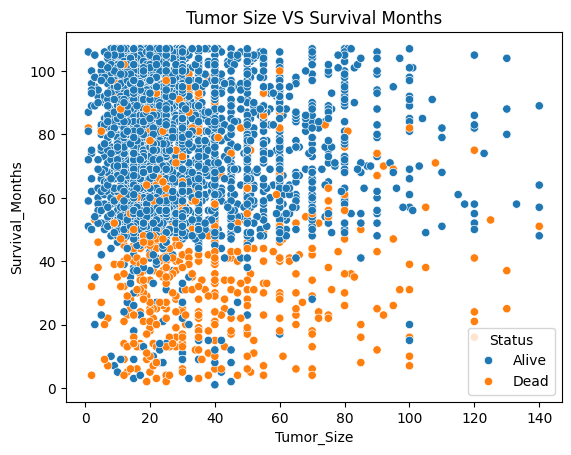

In [52]:
#scatter plot
sns.scatterplot(data = df, x= "Tumor_Size", y= "Survival_Months", hue= "Status")
plt.title("Tumor Size VS Survival Months")

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'IIA'),
  Text(1, 0, 'IIB'),
  Text(2, 0, 'IIIA'),
  Text(3, 0, 'IIIB'),
  Text(4, 0, 'IIIC')])

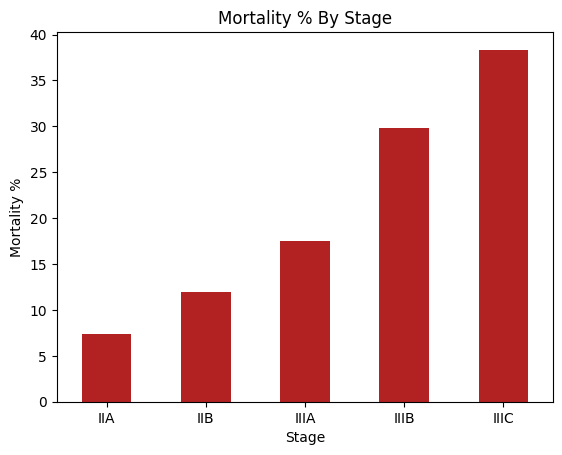

In [53]:
#bar plot
df.groupby("Stage")["Dead"].mean().mul(100).plot(kind = "bar", color = "firebrick")
plt.title("Mortality % By Stage")
plt.ylabel("Mortality %")
plt.xticks(rotation=0)

Text(0, 0.5, 'Number of Deaths')

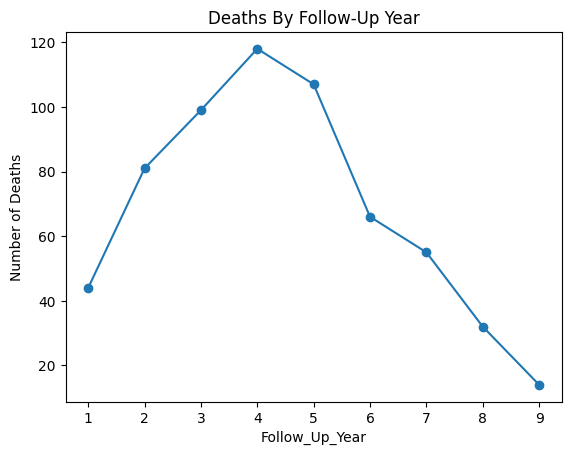

In [54]:
#line plot
df[df["Dead"] == 1].groupby("Follow_Up_Year").size().plot(marker= "o")
plt.title("Deaths By Follow-Up Year")
plt.ylabel("Number of Deaths")

Text(0, 0.5, 'Mortality Rate (0 to 1)')

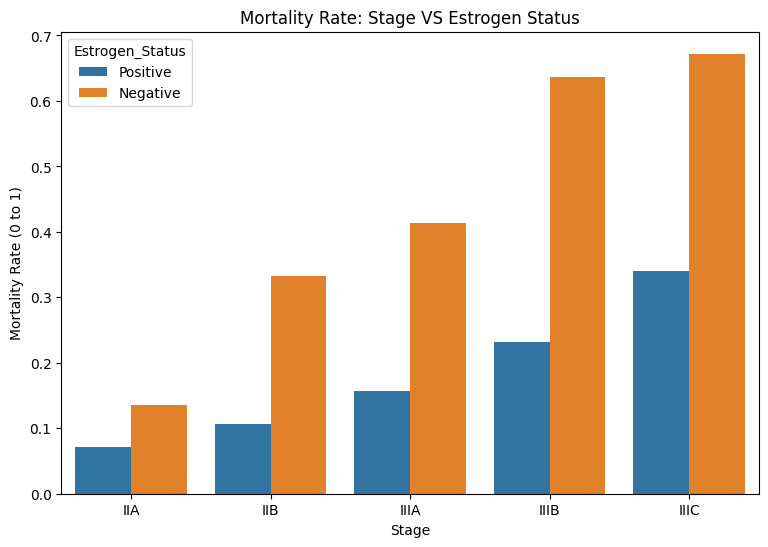

In [55]:
#Grouped bar
plt.figure(figsize= (9, 6))
sns.barplot(data= df, x= "Stage", y= "Dead", hue= "Estrogen_Status", order = ["IIA", "IIB", "IIIA", "IIIB", "IIIC"], errorbar= None)
plt.title("Mortality Rate: Stage VS Estrogen Status")
plt.ylabel("Mortality Rate (0 to 1)")

Text(0.5, 1.0, 'All Numeric Columns Relationship')

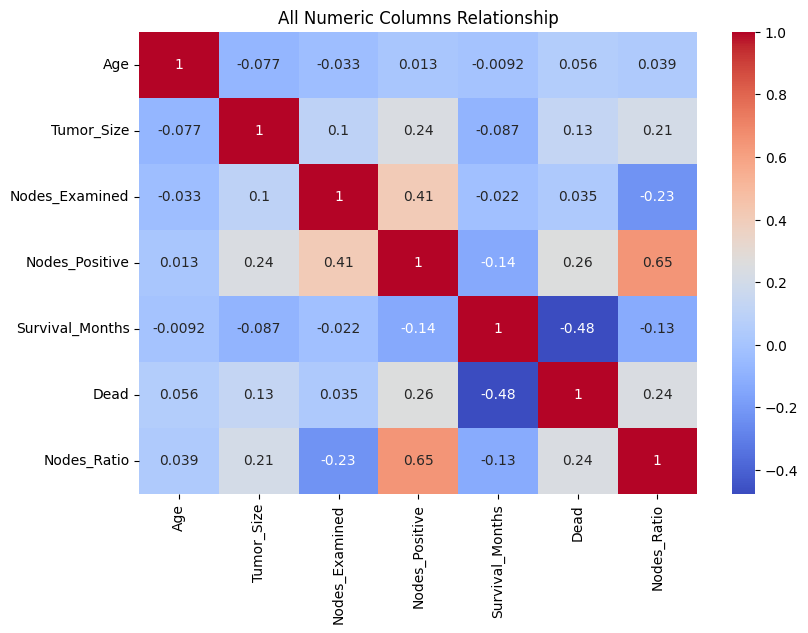

In [58]:
#heatmap
plt.figure(figsize= (9,6))
sns.heatmap(df[["Age", "Tumor_Size", "Nodes_Examined", "Nodes_Positive", "Survival_Months", "Dead", "Nodes_Ratio"]].corr(), annot= True, cmap= "coolwarm")
plt.title("All Numeric Columns Relationship")

# Insights

## Case 1: Tumor Size vs Survival Months

In [58]:
# Graph: Scatter plot of Tumor_Size vs Survival_Months (colored by Status).
# Observation: Points are widely scattered with no clear line. Correlation is only about -0.09, which is very weak.
# Dead patients have a slightly bigger average tumor (~37 mm) than alive patients (~29 mm).
# Insight: Tumor size alone does not decide how long a patient survives. Survival_Months has the strongest relation with Dead (-0.48),
# but that is just follow-up time. Positive lymph nodes (0.26) matter more than tumor size (0.13).
# Decision: Do not judge risk by tumor size alone. Check lymph node involvement and hormone status together.

## Case 2: Stage vs Mortality

In [ ]:
# Graph: Bar chart of Mortality % by Stage.
# Observation: Mortality rises at every step: IIA ~7.4%, IIB ~11.9%, IIIA ~17.5%, IIIB ~29.9%, IIIC ~38.3%. IIIC is about 5 times worse than IIA.
# Insight: Cancer found at a later stage is far more dangerous. Stage is the clearest risk factor in this data.
# Decision: Promote early screening so more patients are found in Stage II. Give Stage IIIB/IIIC patients the most intensive follow-up.

## Case 3: Stage vs Estrogen Status

In [ ]:
# Graph: Grouped bar chart / pivot table of Mortality by Stage and Estrogen Status.
# Observation: At every stage, estrogen negative patients die more. Example: Stage IIIA ~41.3% vs ~15.7%, Stage IIIC ~67.2% vs ~34.1%.
# Insight: Estrogen negative status makes every stage worse (about 2 to 3 times higher mortality). Estrogen negative + late stage is the highest-risk group.
# Decision: Treat estrogen negative patients as high priority from day one, with closer monitoring and early referral to specialist care.
# Limitation: Estrogen negative groups are small (e.g. only 11 patients in Stage IIIB), so those rates are less reliable. No date or treatment data exists.